In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wordcloud import WordCloud, STOPWORDS

In [2]:
%pip install scikit-learn pandas
%pip install pyarrow


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pwd
df = pd.read_parquet("../sampleddata.parquet")
print(df.shape)
df.head()

(465146, 21)


,tweet_id,text,media,retweetedTweet,lang,rawContent,replyCount,retweetCount,likeCount,quoteCount,...,mentionedUsers,links,viewCount,quotedTweet,in_reply_to_screen_name,location,user,date,week,cleanedTweet
0,1822052939076141150,"Read ""Conservative warns MAGA fans Trump 'coul...",[],False,en,"Read ""Conservative warns MAGA fans Trump 'coul...",0.0,0.0,0.0,0.0,...,[],[{'display_url': 'l.smartnews.com/p-rbqCZ/22rm...,"{'count': '4', 'state': 'EnabledWithCount'}",False,NaN,NaN,"{'id': 1441751938719121415, 'id_str': '1441751...",2024-08-09,14,"Read ""Conservative warns MAGA fans Trump 'coul..."
1,1822044941042004254,"@lululuvshollis Well, all the millionaires you...",[],False,en,"@lululuvshollis Well, all the millionaires you...",0.0,0.0,0.0,0.0,...,"[{'id_str': '824312677904351238', 'name': 'LuL...",[],"{'count': '4', 'state': 'EnabledWithCount'}",False,lululuvshollis,NaN,"{'id': 1507732343427002373, 'id_str': '1507732...",2024-08-09,14,"Well, all the millionaires you’re referring to..."
2,1822032912381776359,@gatewaypundit That ahhhh…..that’s not legal. ...,[],False,en,@gatewaypundit That ahhhh…..that’s not legal. ...,0.0,1.0,25.0,0.0,...,"[{'id_str': '19211550', 'name': 'The Gateway P...",[],"{'count': '739', 'state': 'EnabledWithCount'}",False,gatewaypundit,NaN,"{'id': 35338824, 'id_str': '35338824', 'url': ...",2024-08-09,14,That ahhhh.....that’s not legal. Which SS offi...
3,1822041814712643713,@SUENUTTER115928 @its_The_Dr I see the sign sa...,[],False,en,@SUENUTTER115928 @its_The_Dr I see the sign sa...,2.0,0.0,1.0,0.0,...,"[{'id_str': '1751057710299160576', 'name': '🇺🇸...",[],"{'count': '12', 'state': 'EnabledWithCount'}",False,SUENUTTER115928,NaN,"{'id': 1352623760365375491, 'id_str': '1352623...",2024-08-09,14,I see the sign says Biden 2020. The picture wa...
4,1822044641534849202,@EdKrassen Why is Ed so obsessed with Donald T...,[],False,en,@EdKrassen Why is Ed so obsessed with Donald T...,0.0,0.0,0.0,0.0,...,"[{'id_str': '132339474', 'name': 'Ed Krassenst...",[],"{'count': '6', 'state': 'EnabledWithCount'}",False,EdKrassen,NaN,"{'id': 1336456304089559041, 'id_str': '1336456...",2024-08-09,14,Why is Ed so obsessed with Donald Trump?


In [4]:
df.describe()

,tweet_id,replyCount,retweetCount,likeCount,quoteCount,week
count,4.651460e+05,465146.000000,465146.000000,465146.000000,465146.000000,465146.000000
mean,1.824799e+18,5.870447,12.690368,64.915463,0.915927,15.003427
std,2.261485e+16,193.625026,377.758684,2107.045061,30.888848,8.944487
min,1.785459e+18,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.804466e+18,0.000000,0.000000,0.000000,0.000000,7.000000
50%,1.824808e+18,0.000000,0.000000,0.000000,0.000000,15.000000
75%,1.844523e+18,0.000000,0.000000,1.000000,0.000000,23.000000
max,1.863010e+18,29698.000000,81676.000000,389235.000000,7468.000000,30.000000


In [5]:
df.groupby('week')[['retweetCount','likeCount']].describe()

retweetCount                                                       \
            count       mean          std  min  25%  50%  75%      max   
week                                                                     
0         14985.0   4.243510    81.088734  0.0  0.0  0.0  0.0   5184.0   
1         14991.0   8.358415   206.270873  0.0  0.0  0.0  0.0  13876.0   
2         14980.0  20.136515   343.371186  0.0  0.0  0.0  0.0  21343.0   
3         14990.0  21.847432   410.996035  0.0  0.0  0.0  0.0  31455.0   
4         14990.0  38.534823   589.854958  0.0  0.0  0.0  0.0  28376.0   
5         14977.0  10.307405   208.464090  0.0  0.0  0.0  0.0  12918.0   
6         15023.0   3.964787   100.170698  0.0  0.0  0.0  0.0   8208.0   
7         14998.0   4.777237   140.898211  0.0  0.0  0.0  0.0  15826.0   
8         15018.0   5.181249   125.576348  0.0  0.0  0.0  0.0  12581.0   
9         15079.0   4.131773   100.911766  0.0  0.0  0.0  0.0   7590.0   
10        15027.0   2.995874    69.723001  0.0  0.0  0.0  0.0   6291.0   
11        15002.0   5.924877   183.078237  0.0  0.0  0.0  0.0  11911.0   
12        15021.0  15.012183   415.901247  0.0  0.0  0.0  0.0  34723.0   
13        14997.0   8.074415   261.013169  0.0  0.0  0.0  0.0  25733.0   
14        14952.0   6.098783   192.747258  0.0  0.0  0.0  0.0  18816.0   
15        15049.0   4.897335   120.117933  0.0  0.0  0.0  0.0  10029.0   
16        15008.0   5.736541   144.697761  0.0  0.0  0.0  0.0  13578.0   
17        14997.0   8.919851   182.891455  0.0  0.0  0.0  0.0  10547.0   
18        14997.0   8.248450   211.738358  0.0  0.0  0.0  0.0  20993.0   
19        14972.0  13.168715   440.807881  0.0  0.0  0.0  0.0  48749.0   
20        14903.0   6.246058   174.480266  0.0  0.0  0.0  0.0  11784.0   
21        14976.0  11.632011   272.650383  0.0  0.0  0.0  0.0  20677.0   
22        15030.0  12.004790   311.767572  0.0  0.0  0.0  0.0  21779.0   
23        15069.0   4.744708   127.360968  0.0  0.0  0.0  0.0  10393.0   
24        15005.0   1.659247    88.337092  0.0  0.0  0.0  0.0   8278.0   
25        15011.0  22.190793   550.864130  0.0  0.0  0.0  0.0  37867.0   
26        15007.0  87.171986  1348.639013  0.0  0.0  0.0  0.0  81676.0   
27        14987.0  34.921065   779.340745  0.0  0.0  0.0  0.0  70837.0   
28        15056.0   5.915848   168.840870  0.0  0.0  0.0  0.0  16390.0   
29        15087.0   4.207861   151.458882  0.0  0.0  0.0  0.0  16329.0   
30        14962.0   2.277236    49.244130  0.0  0.0  0.0  0.0   3465.0   

     likeCount                                                         
         count        mean          std  min  25%  50%  75%       max  
week                                                                   
0      14985.0   17.334201   284.575834  0.0  0.0  0.0  1.0   15707.0  
1      14991.0   41.939831  1503.172712  0.0  0.0  0.0  1.0  165302.0  
2      14980.0  107.805140  2017.363283  0.0  0.0  0.0  2.0  169781.0  
3      14990.0  100.257171  1989.230948  0.0  0.0  0.0  1.0  177670.0  
4      14990.0  188.512942  3510.181194  0.0  0.0  0.0  1.0  300653.0  
5      14977.0   50.455098  1107.991937  0.0  0.0  0.0  1.0   85288.0  
6      15023.0   20.030487   608.024039  0.0  0.0  0.0  1.0   65507.0  
7      14998.0   18.191225   456.756816  0.0  0.0  0.0  1.0   48835.0  
8      15018.0   26.705953   675.144892  0.0  0.0  0.0  1.0   65065.0  
9      15079.0   16.621527   368.326190  0.0  0.0  0.0  1.0   26552.0  
10     15027.0   18.341718   526.694952  0.0  0.0  0.0  1.0   46237.0  
11     15002.0   38.590721  1347.369920  0.0  0.0  0.0  1.0   97984.0  
12     15021.0   66.716863  1667.647723  0.0  0.0  0.0  1.0  110408.0  
13     14997.0   33.092485   853.129515  0.0  0.0  0.0  1.0   52084.0  
14     14952.0   27.597646   758.890795  0.0  0.0  0.0  1.0   70093.0  
15     15049.0   20.103196   425.266337  0.0  0.0  0.0  1.0   30348.0  
16     15008.0   27.234542   697.021016  0.0  0.0  0.0  1.0   65049.0  
17     14997.0   33.223445   619.913781  0.0  0.

In [6]:
df['cleanedTweet']

0         Read "Conservative warns MAGA fans Trump 'coul...
1         Well, all the millionaires you’re referring to...
2         That ahhhh.....that’s not legal. Which SS offi...
3         I see the sign says Biden 2020. The picture wa...
4                  Why is Ed so obsessed with Donald Trump?
                                ...                        
465141    Will not the involvement of DC be considered a...
465142    The left is too small for AOC fans to cut out ...
465143    How can Kamala Harris even show her face in pu...
465144    John legend is a dnc shill and his wife is vil...
465145                                 about Harris is fake
Name: cleanedTweet, Length: 465146, dtype: str

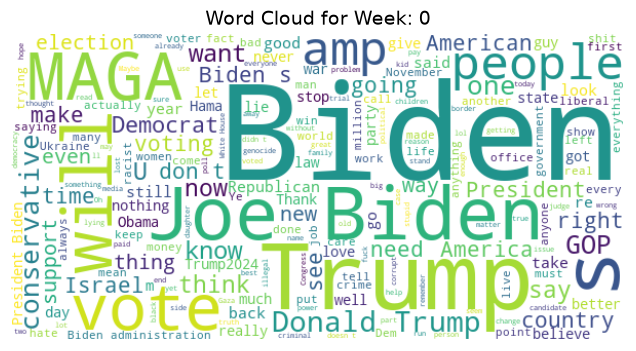

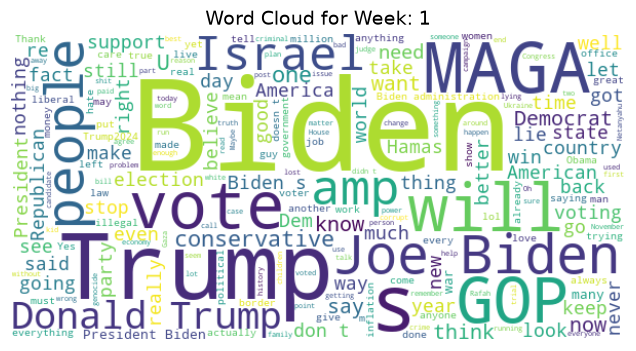

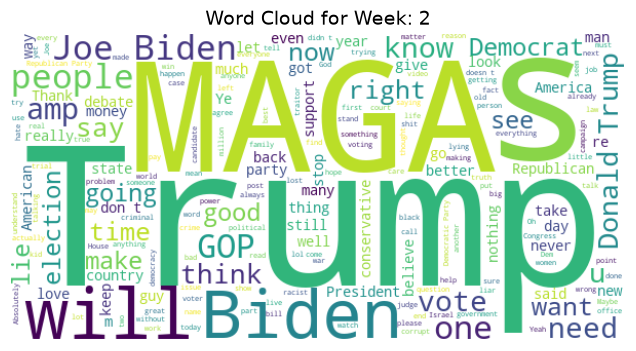

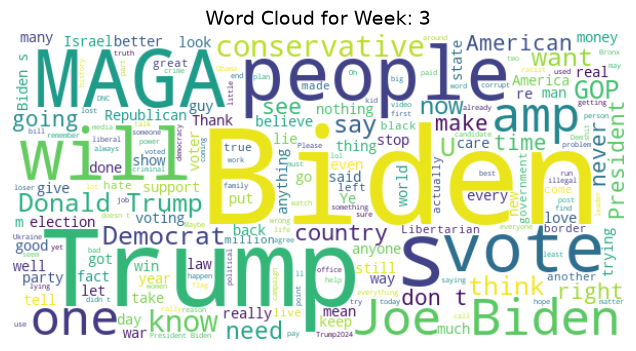

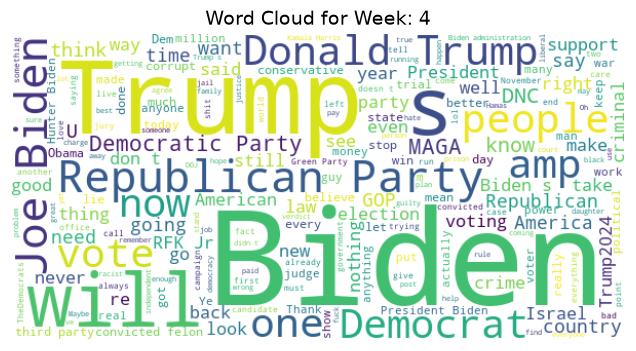

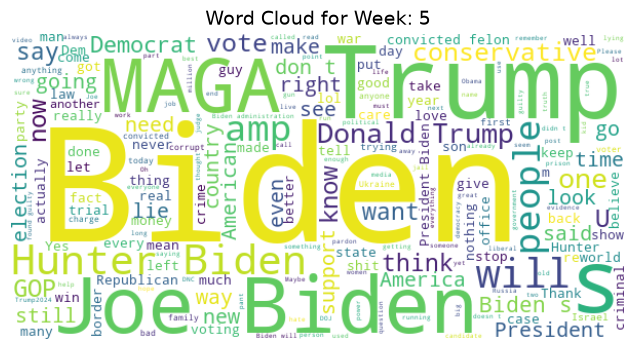

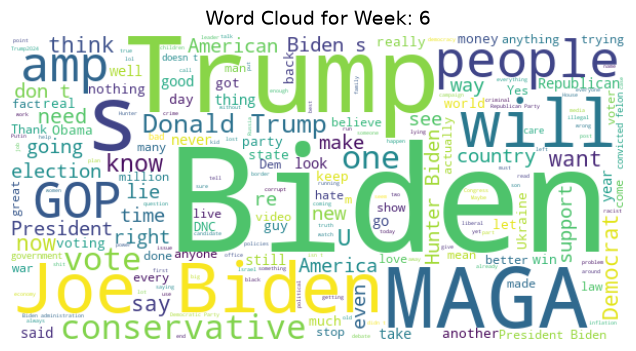

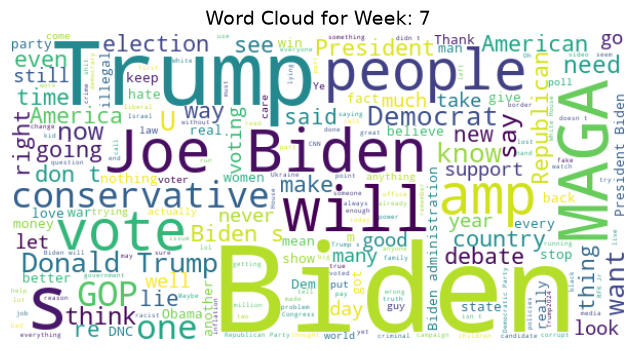

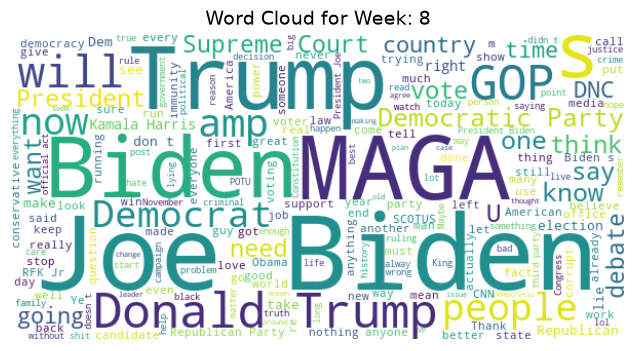

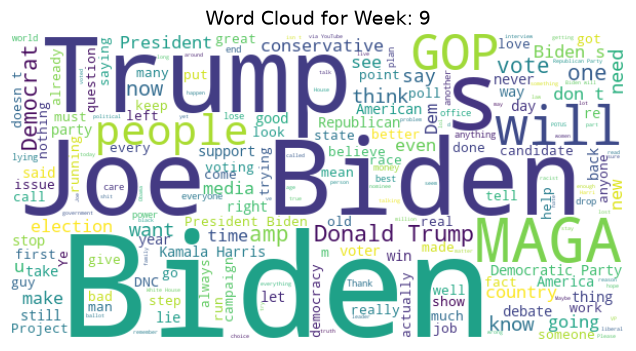

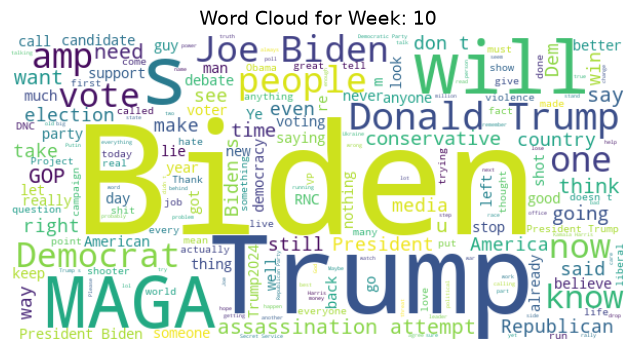

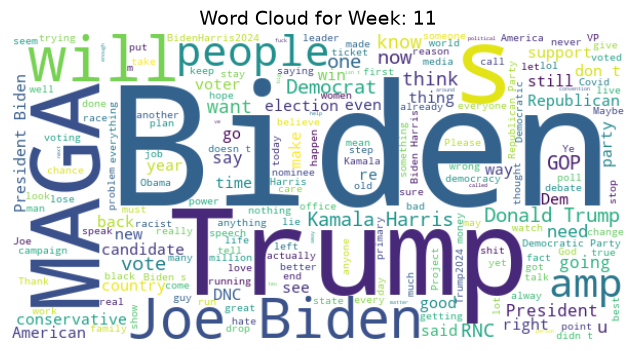

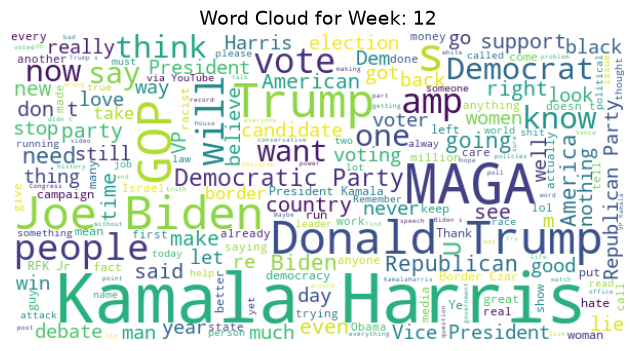

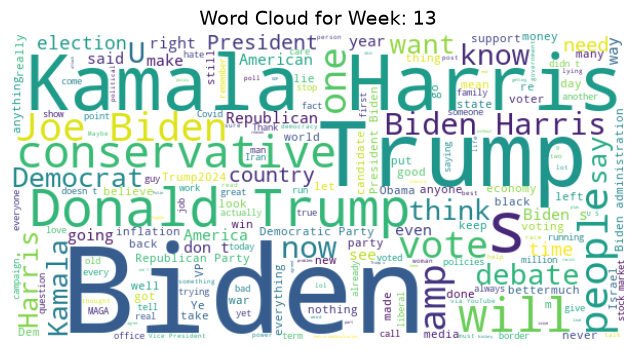

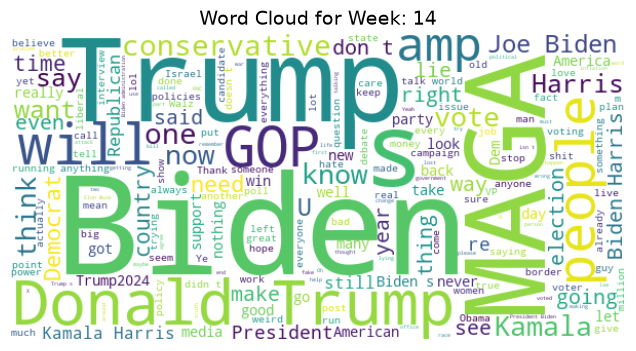

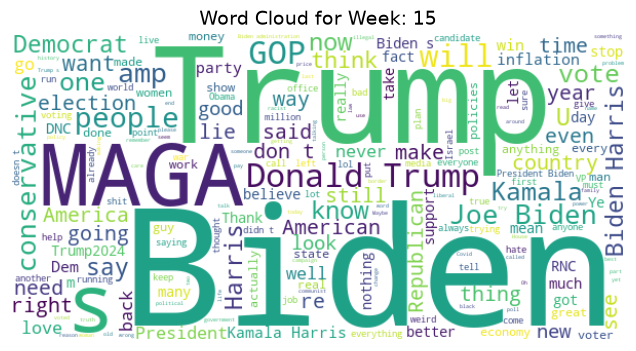

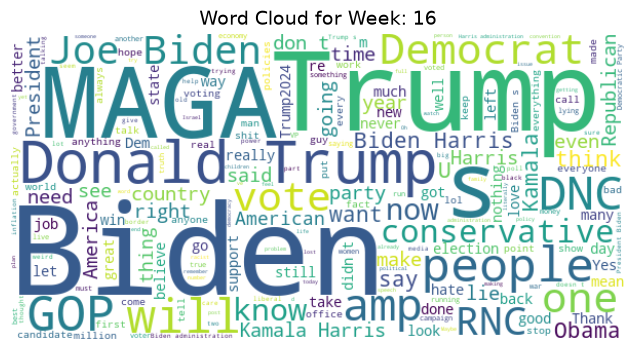

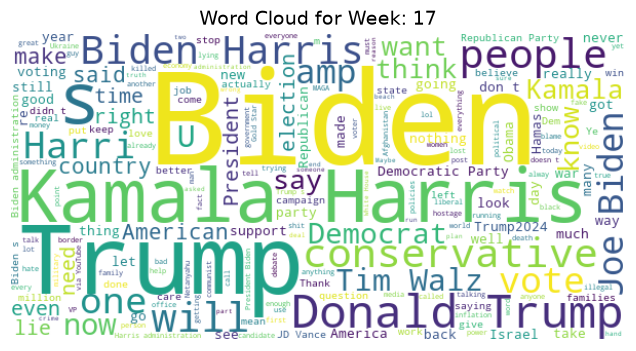

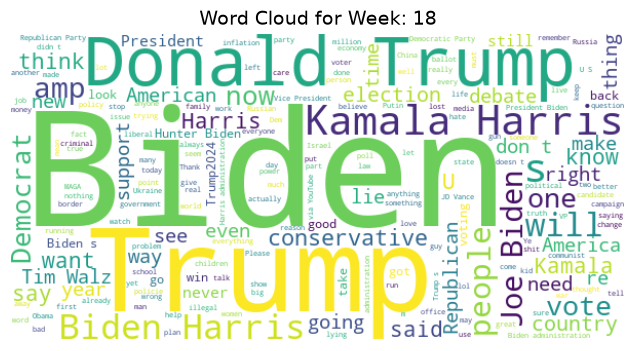

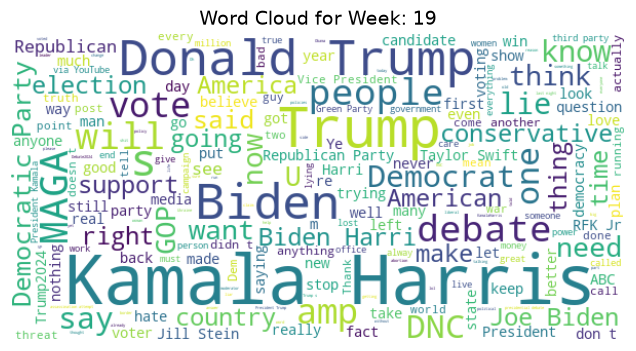

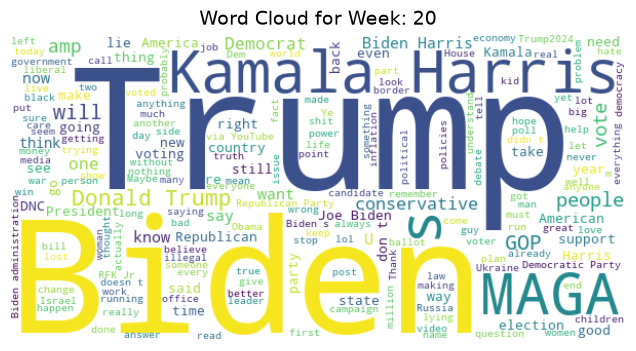

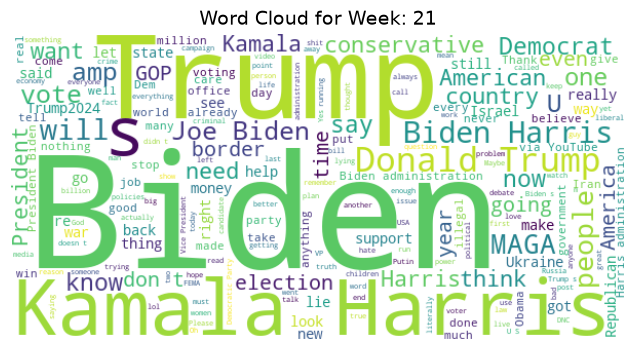

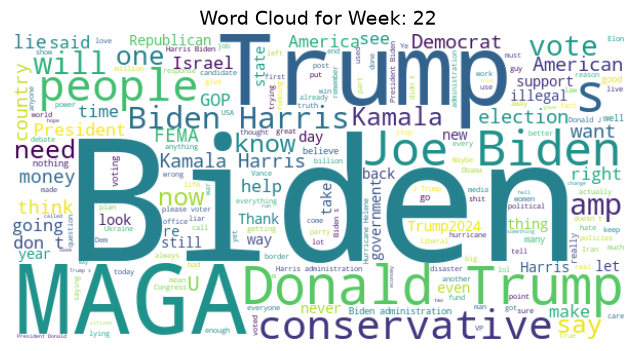

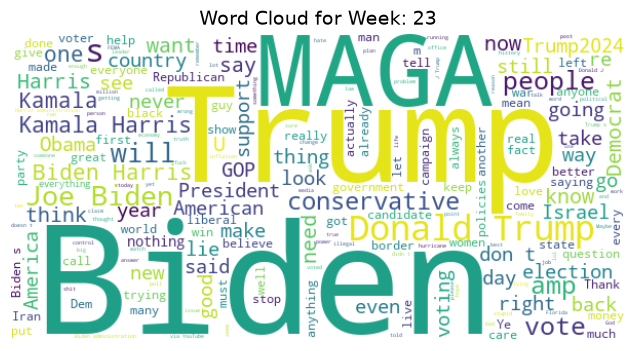

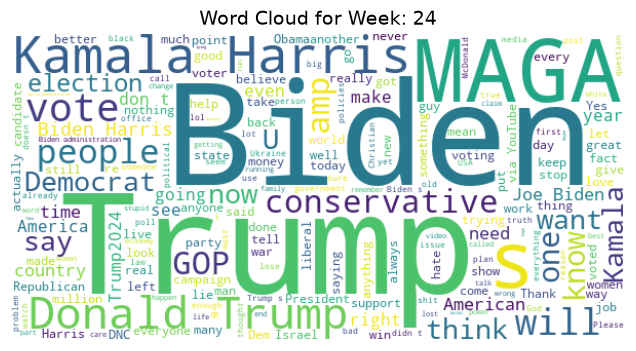

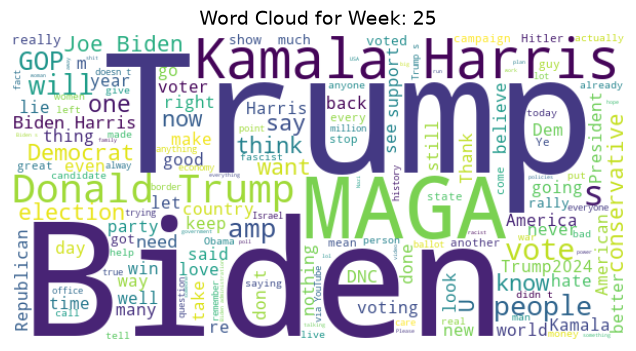

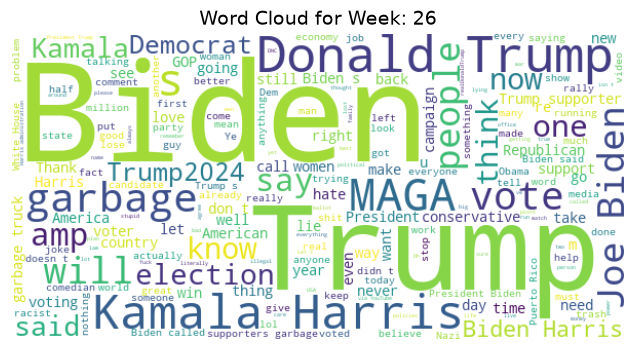

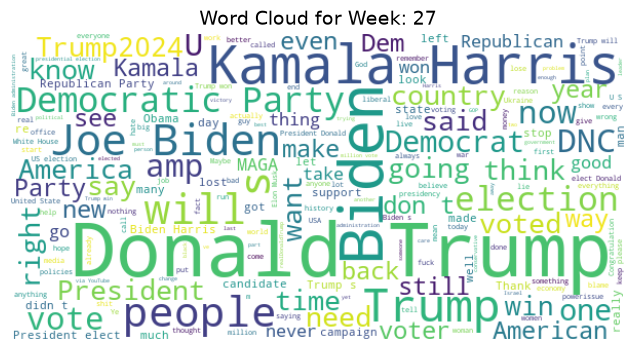

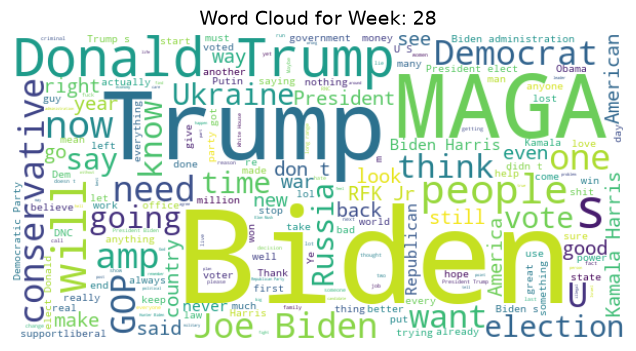

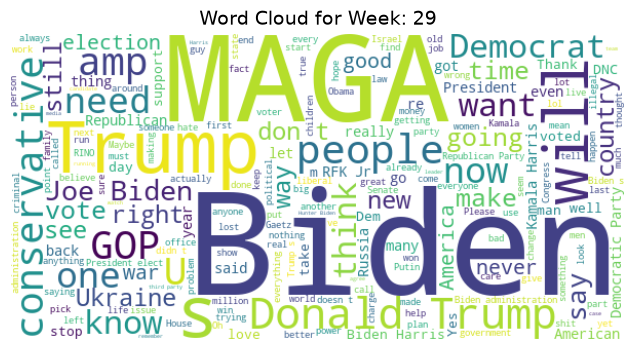

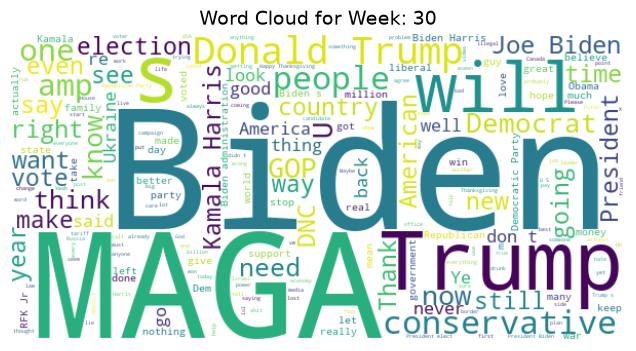

In [7]:
weekly_words = df.groupby('week')['cleanedTweet'].agg(' '.join)
stopwords = set(STOPWORDS)

for index, week in enumerate(weekly_words):
    # Generate the word cloud
    wordcloud = WordCloud(
        width=600,
        height=300,
        background_color='white',
        stopwords=set(STOPWORDS)
    ).generate(week)

    # Display the word cloud labeled by the week ending date
    plt.figure(figsize=(8, 4))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f"Word Cloud for Week: {index}", fontsize=14)
    plt.axis('off')
    plt.show()

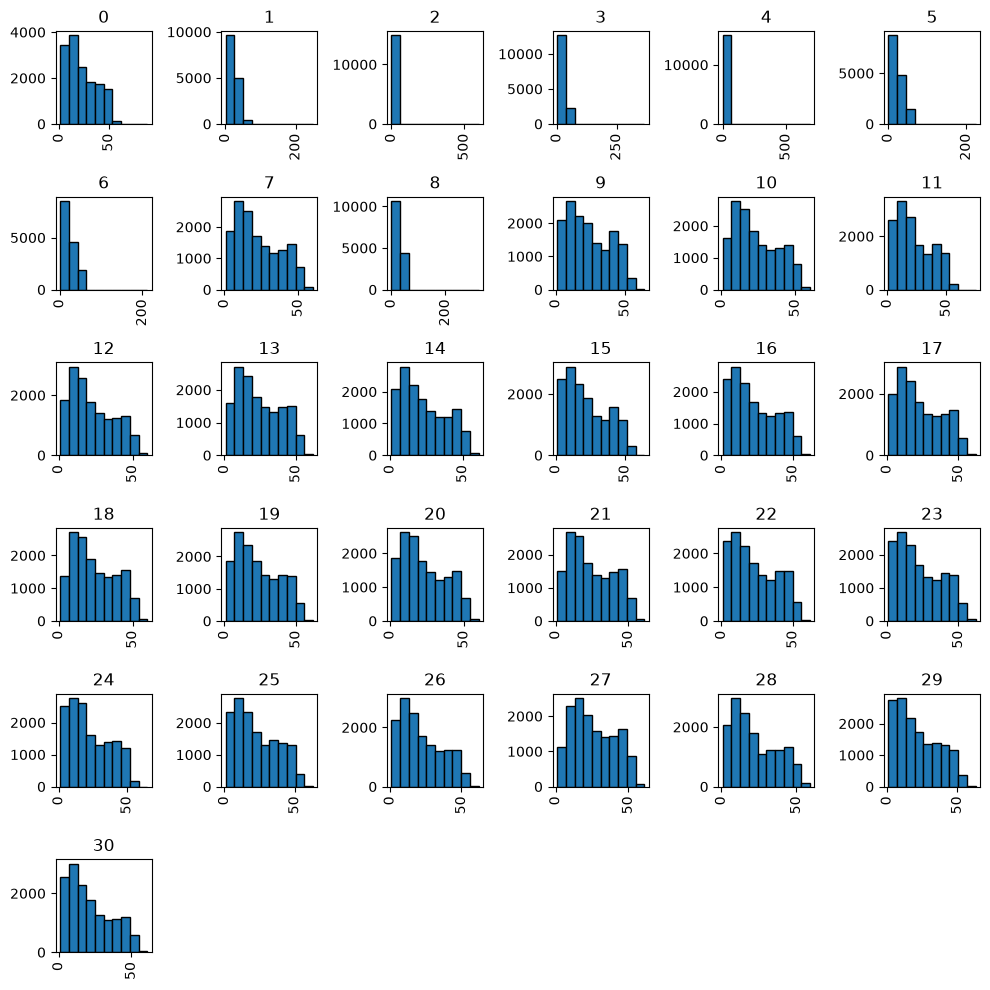

In [8]:
df['tweet_length'] = df['cleanedTweet'].str.split().str.len()
grouped = df.groupby('week')

df.hist(column='tweet_length', by='week', edgecolor='black',figsize=(10,10))
plt.tight_layout()
plt.show()

In [9]:
df.groupby('week')['tweet_length'].describe()

,count,mean,std,min,25%,50%,75%,max
week,,,,,,,,
0,14985.0,22.584918,14.649965,1.0,10.0,19.0,35.0,89.0
1,14991.0,21.723167,14.963940,1.0,9.0,18.0,33.0,249.0
2,14980.0,16.841455,16.896476,1.0,6.0,12.0,23.0,600.0
3,14990.0,19.434823,16.237274,1.0,7.0,15.0,29.0,366.0
4,14990.0,23.130954,17.671999,1.0,10.0,20.0,35.0,690.0
5,14977.0,22.923616,14.752364,1.0,11.0,19.0,35.0,224.0
6,15023.0,22.609066,14.671785,1.0,10.0,19.0,34.0,212.0
7,14998.0,22.914189,14.719077,1.0,10.0,19.0,35.0,60.0
8,15018.0,23.579838,15.163891,1.0,11.0,21.0,36.0,323.0


# Topic Modeling: LDA & NMF (TKG)


This portion of the notebook used unsupervised topic modeling (LDA and NMF) on the cleaned
tweets to identify the main discussion themes and track how they shift week
to week during the campaign.

In [10]:
#Uses Jesse's cleanedTweet column to drop missing values. 
docs=df["cleanedTweet"].dropna().astype(str)
#Creating a new dataframe with only tweets that have 5 or more words for meaningful for analysis.
docs=docs[docs.str.split().str.len() >= 5]
print(len(docs), "tweets used for topic modeling")
docs.head(10)

431673 tweets used for topic modeling


0     Read "Conservative warns MAGA fans Trump 'coul...
1     Well, all the millionaires you’re referring to...
2     That ahhhh.....that’s not legal. Which SS offi...
3     I see the sign says Biden 2020. The picture wa...
4              Why is Ed so obsessed with Donald Trump?
5     Not going to happen, the Dems have a lock on t...
6     Matt I appreciate you saying that. Politics ha...
8     trump fabricates helicopter story, didn't happ...
9                 Where is Biden? 🐊 inhabits this place
10    is a great resource for all bible teachers. Li...
Name: cleanedTweet, dtype: str

In [11]:
#Fit LDA and NMF models to the cleaned tweets. This will help identify underlying topics in the tweets.
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF

# Number of topics for topic modeling. This can be adjusted based on the desired granularity of topics.
N_TOPICS = 5

# LDA (Latent Dirichlet Allocation)
# max_df=0.95 ignores words that appear in more than 95% of tweets;
# min_df=5 ignores words that appear in fewer than 5 tweets
count_vec = CountVectorizer(stop_words="english", max_df=0.95, min_df=5)
X_counts = count_vec.fit_transform(docs)
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42)
lda.fit(X_counts)

#NMF (Non-negative Matrix Factorization)
tfidf_vec = TfidfVectorizer(stop_words="english", max_df=0.95, min_df=5)
X_tfidf = tfidf_vec.fit_transform(docs)
nmf = NMF(n_components=N_TOPICS, init="nndsvd", random_state=42, max_iter=500)
nmf.fit(X_tfidf)

# random_state=42 makes results repeatable, so everyone gets the same topics




,"n_components n_components: int or {'auto'} or None, default='auto'Number of components. If `None`, all features are kept.If `n_components='auto'`, the number of components is automatically inferredfrom W or H shapes... versionchanged:: 1.4 Added `'auto'` value... versionchanged:: 1.6 Default value changed from `None` to `'auto'`.",5
,"init init: {'random', 'nndsvd', 'nndsvda', 'nndsvdar', 'custom'}, default=NoneMethod used to initialize the procedure.Valid options:- `None`: 'nndsvda' if n_components <= min(n_samples, n_features), otherwise random.- `'random'`: non-negative random matrices, scaled with: `sqrt(X.mean() / n_components)`- `'nndsvd'`: Nonnegative Double Singular Value Decomposition (NNDSVD) initialization (better for sparseness)- `'nndsvda'`: NNDSVD with zeros filled with the average of X (better when sparsity is not desired)- `'nndsvdar'` NNDSVD with zeros filled with small random values (generally faster, less accurate alternative to NNDSVDa for when sparsity is not desired)- `'custom'`: Use custom matrices `W` and `H` which must both be provided... versionchanged:: 1.1 When `init=None` and n_components is less than n_samples and n_features defaults to `nndsvda` instead of `nndsvd`.",'nndsvd'
,"max_iter max_iter: int, default=200Maximum number of iterations before timing out.",500
,"random_state random_state: int, RandomState instance or None, default=NoneUsed for initialisation (when ``init`` == 'nndsvdar' or'random'), and in Coordinate Descent. Pass an int for reproducibleresults across multiple function calls.See :term:`Glossary <random_state>`.",42
,"solver solver: {'cd', 'mu'}, default='cd'Numerical solver to use:- 'cd' is a Coordinate Descent solver.- 'mu' is a Multiplicative Update solver... versionadded:: 0.17 Coordinate Descent solver... versionadded:: 0.19 Multiplicative Update solver.",'cd'
,"beta_loss beta_loss: float or {'frobenius', 'kullback-leibler', 'itakura-saito'}, default='frobenius'Beta divergence to be minimized, measuring the distance between Xand the dot product WH. Note that values different from 'frobenius'(or 2) and 'kullback-leibler' (or 1) lead to significantly slowerfits. Note that for beta_loss <= 0 (or 'itakura-saito'), the inputmatrix X cannot contain zeros. Used only in 'mu' solver... versionadded:: 0.19",'frobenius'
,"tol tol: float, default=1e-4Tolerance of the stopping condition.",0.0001
,"alpha_W alpha_W: float, default=0.0Constant that multiplies the regularization terms of `W`. Set it to zero(default) to have no regularization on `W`... versionadded:: 1.0",0.0
,"alpha_H alpha_H: float or ""same"", default=""same""Constant that multiplies the regularization terms of `H`. Set it to zero tohave no regularization on `H`. If ""same"" (default), it takes the same value as`alpha_W`... versionadded:: 1.0",'same'
,"l1_ratio l1_ratio: float, default=0.0The regularization mixing parameter, with 0 <= l1_ratio <= 1.For l1_ratio = 0 the penalty is an elementwise L2 penalty(aka Frobenius Norm).For l1_ratio = 1 it is an elementwise L1 penalty.For 0 < l1_ratio < 1, the penalty is a combination of L1 and L2... versionadded:: 0.17 Regularization parameter *l1_ratio* used in the Coordinate Descent solver.",0.0
,"verbose verbose: int, default=0Whether to be verbose.",0


In [12]:
#TOPICS
# Prints the top words for each topic so we can interpret what each one is about
def show_topics(model, vectorizer, n_words=10):
    words = vectorizer.get_feature_names_out()
    for i, topic in enumerate(model.components_):
        #Sorts words by how strongly they belong to this topic and keep the top n
        top = [words[j] for j in topic.argsort()[-n_words:][::-1]]
        print(f"Topic {i}: {', '.join(top)}")

# Compare the two models: which gives clearer, less overlapping topics?
print("--- LDA---")
show_topics(lda, count_vec)
print("\n--- NMF ---")
show_topics(nmf, tfidf_vec)

--- LDA---
Topic 0: trump, donald, president, harris, kamala, biden, maga, america, election, trump2024
Topic 1: trump, maga, gop, vote, don, donald, conservative, republican, amp, party
Topic 2: biden, harris, kamala, trump, did, administration, joe, border, people, money
Topic 3: biden, like, just, joe, people, maga, don, trump, know, think
Topic 4: biden, party, amp, conservative, democratic, israel, war, ukraine, russia, government

--- NMF ---
Topic 0: biden, joe, president, did, administration, hunter, like, obama, years, just
Topic 1: trump, donald, president, america, election, 2024, vote, debate, god, win
Topic 2: harris, kamala, president, vp, vote, youtube, debate, campaign, vice, administration
Topic 3: maga, cult, trump2024, america, just, trump, great, make, love, hat
Topic 4: party, people, vote, don, like, democratic, republican, conservative, just, gop


<Axes: title={'center': 'NMF topic share by week'}, xlabel='week'>

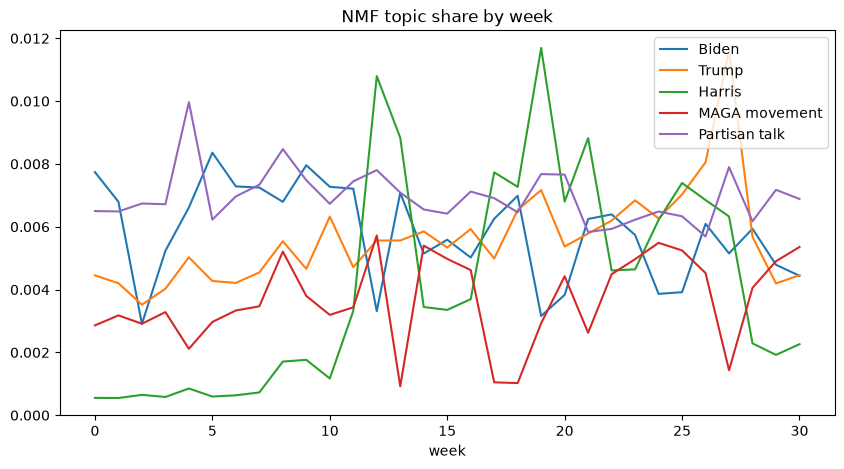

In [13]:
#Topics Over Time
# How much each of the NMF topics shows up in each week of the campaign;
# rising/falling lines show which narratives gained or lost attention
doc_topics = nmf.transform(X_tfidf)              
topic_df = pd.DataFrame(doc_topics, index=docs.index)
topic_df["week"] = df.loc[docs.index, "week"]    

weekly_topics = topic_df.groupby("week").mean()
weekly_topics.columns = [
    "Biden",
    "Trump",
    "Harris",
    "MAGA movement",
    "Partisan talk",
]
weekly_topics.plot(figsize=(10, 5), title="NMF topic share by week")

## Testing More Topics (20 and 30)

At 5 topics, both models grouped tweets by candidate (Biden, Trump, MAGA, Harris, partisan talk) instead of by issue. To check whether more topics would surface issue topics, we reran LDA and NMF at 20 and 30 topics. Candidate names, party labels, and filler words were added to the stop words, and "max_df" was lowered to 0.5 so very common words are dropped.

(These runs are exploritory & separate from the 5-topic NMF above, which the rest of the notebook still uses.)

In [14]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Candidate names, party labels, and filler words show up in so many tweets that they
# take over the topics, so we remove them to let issue words come through
name_stops = {
    "trump", "trumps", "donald", "biden", "bidens", "joe", "harris", "harriss", "kamala", "kamalas",
    "maga", "vance", "walz", "jd", "tim", "president", "election", "vote", "voting",
    "democrats", "republicans", "democrat", "republican", "gop",
    "amp", "don", "didn", "just", "like", "did", "know", "let", "said", "people", "doesn", "isn",
    "going", "think", "want", "right", "need", "make", "way", "say", "really", "ve", "ll",
    "good", "time", "got", "does",
}
k_stops = list(ENGLISH_STOP_WORDS.union(name_stops))

# max_df=0.5 drops words that appear in more than half the tweets
count_vec_k = CountVectorizer(stop_words=k_stops, max_df=0.5, min_df=5)
X_counts_k = count_vec_k.fit_transform(docs)
tfidf_vec_k = TfidfVectorizer(stop_words=k_stops, max_df=0.5, min_df=5)
X_tfidf_k = tfidf_vec_k.fit_transform(docs)

# Fit LDA and NMF at 20 and 30 topics (same random_state so results are repeatable)
topic_runs = {}
for k in [20, 30]:
    topic_runs[("LDA", k)] = LatentDirichletAllocation(n_components=k, random_state=42).fit(X_counts_k)
    topic_runs[("NMF", k)] = NMF(n_components=k, init="nndsvd", random_state=42, max_iter=500).fit(X_tfidf_k)

for (name, k), model in topic_runs.items():
    print(f"\n--- {name}, {k} topics ---")
    show_topics(model, count_vec_k if name == "LDA" else tfidf_vec_k)


--- LDA, 20 topics ---
Topic 0: conservative, party, liberal, anti, green, government, conservatives, pro, christian, movement
Topic 1: yes, fake, 000, care, wouldn, history, administration, haley, dumb, nikki
Topic 2: states, united, jill, red, blue, thought, dementia, old, saying, stein
Topic 3: white, house, running, men, senate, weird, hold, garbage, stay, racist
Topic 4: america, country, democracy, needs, world, evil, save, corrupt, border, law
Topic 5: black, voters, candidate, dnc, dems, attempt, assassination, nominee, run, step
Topic 6: state, project, change, 2025, deep, desantis, pelosi, endorsed, florida, george
Topic 7: illegal, american, americans, illegals, citizens, open, border, children, immigrants, country
Topic 8: hunter, media, lies, lie, case, doj, evidence, guilty, lied, video
Topic 9: debate, news, youtube, rally, rnc, cnn, polls, poll, fox, jr
Topic 10: ukraine, war, 2024, votes, 2020, million, russia, win, year, elections
Topic 11: love, god, oh, thank, fami

Findings:

- 20 topics: only a few topics were issue related, and they mixed several issues together (for example, NMF gave one topic with border, israel, war, immigration, and inflation).
- 30 topics: LDA separated out clearer issue topics: economy (inflation, economy, jobs, prices, gas, cost), immigration (border, illegal, illegals), foreign policy (war, russia, ukraine; and israel, hamas, netanyahu), a mixed abortion topic (women, rights, abortion), and courts (supreme court). NMF at 30 changed little from 20.
- Most other topics are  campaignevents (RFK Jr., the DNC and RNC, the assassination attempt), reactions, and hashtags rather than issues.

The main reason is the data itself: only a small amount of the tweets mention any issue (see the issue coverage check below). Adding topics mostly splits the non issue chatter into smaller pieces instead of surfacing new issues. This is why the next section uses keywords to pull the issue tweets first, then runs NMF within each issue to track how its framing shifts.

## Topic Matching and Shift Scoring

This portion of the notebook we topic matched by pairing each period's topics with the next period's most similar topics. secondly, we do shoift scoring to measure how much the issue's framing changed between periods.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from sklearn.metrics.pairwise import cosine_similarity
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import jensenshannon

print(df.shape)
print(df.columns.tolist())

(465146, 22)
['tweet_id', 'text', 'media', 'retweetedTweet', 'lang', 'rawContent', 'replyCount', 'retweetCount', 'likeCount', 'quoteCount', 'hashtags', 'mentionedUsers', 'links', 'viewCount', 'quotedTweet', 'in_reply_to_screen_name', 'location', 'user', 'date', 'week', 'cleanedTweet', 'tweet_length']


In [ ]:
# Keywords used to consolidate tweet on a given issue.
ISSUE_KEYWORDS = {
    "immigration": r"immigra|border|migrant|asylum|deport|illegals|illegal alien|refugee",
    "economy":     r"econom|inflation|prices|jobs|tax|wages|gas price|groceries",
    "abortion":    r"abortion|\broe\b|roevember|restoreroe|pro.?life|pro.?choice|reproductive|ivf",
    "democracy":   r"democracy|january 6|jan 6|insurrection|stolen election|fascist",
    "foreign_policy": r"ukraine|russia|israel|gaza|china|\bnato\b"}
text = df["cleanedTweet"].fillna("").str.lower()

# One True/False column per issue, named issue_<name> (a tweet can mention more than one issue)
for issue, pattern in ISSUE_KEYWORDS.items():
    df[f"issue_{issue}"] = text.str.contains(pattern, regex=True)

# How many tweets mention each issue
print(df[[f"issue_{i}" for i in ISSUE_KEYWORDS]].sum().sort_values(ascending=False))

issue_foreign_policy    18668
issue_economy           16934
issue_immigration       16178
issue_democracy          8319
issue_abortion           3192
dtype: int64


In [17]:
# Issue coverage: what share of all tweets mention at least one issue
any_issue = df[[f"issue_{i}" for i in ISSUE_KEYWORDS]].any(axis=1)
print(f"{any_issue.sum()} of {len(df)} tweets ({any_issue.mean():.1%}) mention at least one issue")

58345 of 465146 tweets (12.5%) mention at least one issue


In [18]:
ISSUE = "immigration"   # test issue; can be changed to any issue in ISSUE_KEYWORDS
PERIOD_WEEKS = 1        
K = 5                   # number of topics (frames) per period

# tweets about specific issue
issue_df = df[df[f"issue_{ISSUE}"]].copy()
issue_df = issue_df[issue_df["cleanedTweet"].str.split().str.len() >= 5].reset_index(drop=True)

#Assigning issues a period (each week has its own period)
issue_df["period"] = issue_df["week"] // PERIOD_WEEKS

print(len(issue_df), f"tweets about {ISSUE}")
print(issue_df["period"].value_counts().sort_index())  

16099 tweets about immigration
period
0      515
1      520
2      246
3      464
4      349
5      489
6      542
7      809
8      290
9      307
10     244
11     277
12     722
13     679
14     491
15     449
16     448
17     494
18     743
19     571
20     658
21    1130
22     921
23     686
24     484
25     536
26     356
27     418
28     366
29     422
30     473
Name: count, dtype: int64


In [19]:
# Stop typical stopwords/filler words
custom_stops = list(ENGLISH_STOP_WORDS.union(
    {"amp", "don", "didn", "just", "like", "did", "know", "let", "said", "people"}
))

# One shared vocabulary so topics from different periods can be compared
vec = TfidfVectorizer(stop_words=custom_stops, max_df=0.95, min_df=2)
X = vec.fit_transform(issue_df["cleanedTweet"])
words = vec.get_feature_names_out()

def top_words(topic_row, n=8):
    """Top n words for one topic."""
    return ", ".join(words[i] for i in topic_row.argsort()[-n:][::-1])

models = {}
for period, rows in sorted(issue_df.groupby("period").indices.items()):
    X_p = X[rows]
    if X_p.shape[0] < K * 10:   # skip periods with too few tweets
        print(f"Period {period}: only {X_p.shape[0]} tweets, skipped")
        continue
    period_nmf = NMF(n_components=K, init="nndsvd", random_state=42, max_iter=500)
    W = period_nmf.fit_transform(X_p)          # topic scores for each tweet
    props = W.sum(axis=0) / W.sum()            # each topic's share of the period
    models[period] = {"H": period_nmf.components_, "props": props}

    print(f"\n=== Period {period} ({X_p.shape[0]} tweets) ===")
    for t, row in enumerate(period_nmf.components_):
        print(f"  Topic {t} ({props[t]:.0%}): {top_words(row)}")


=== Period 0 (515 tweets) ===
  Topic 0 (25%): illegals, biden, country, illegal, vote, immigrants, money, citizens
  Topic 1 (10%): obamacare, 100k, pamelageller, gives, daca, illegals, biden, uninsured
  Topic 2 (15%): refugees, bring, wants, hamas, palestinian, palestinians, biden, gaza
  Topic 3 (18%): joe, japan, biden, president, xenophobic, deport, calls, india
  Topic 4 (32%): border, open, biden, borders, trump, children, gop, national

=== Period 1 (520 tweets) ===
  Topic 0 (21%): border, gop, trump, biden, secure, bipartisan, maga, republicans
  Topic 1 (24%): illegal, immigrants, aliens, biden, joe, america, country, million
  Topic 2 (22%): illegals, vote, biden, going, elections, democrats, register, voting
  Topic 3 (20%): borders, open, biden, democrats, inflation, trump, joe, hands
  Topic 4 (12%): gaza, plan, refugees, pan, biden, deport, critics, palestinians

=== Period 2 (246 tweets) ===
  Topic 0 (16%): border, secure, close, southern, nope, talk, wall, stand
  

In [20]:
#matching topics across periods
def match_topics(H_a, H_b, threshold=0.2):
    """
    Pair each topic in period A with its most similar topic in period B using cosine similarity of their word weights (1 = identical, 0 = no overlap).
    Pairs below the threshold are "unmatched": a frame that appeared or disappeared.
    """
    sim = cosine_similarity(H_a, H_b)
    rows, cols = linear_sum_assignment(-sim)   # best one-to-one pairing
    return [(a, b, sim[a, b], sim[a, b] >= threshold) for a, b in zip(rows, cols)]

In [21]:
periods = sorted(models)
results = []
for p_a, p_b in zip(periods[:-1], periods[1:]):
    A, B = models[p_a], models[p_b]
    pairs = match_topics(A["H"], B["H"])

    # Content shift: how much matched topics changed wording (0 = same, 1 = totally different)
    matched = [s for _, _, s, ok in pairs if ok]
    content_shift = np.mean([1 - s for s in matched]) if matched else 1.0

    # Proportion shift: how much attention moved between topics (0 = same mix, 1 = completely different)
    a_idx = [a for a, _, _, _ in pairs]
    b_idx = [b for _, b, _, _ in pairs]
    proportion_shift = jensenshannon(A["props"][a_idx], B["props"][b_idx], base=2)

    results.append({
        "from_period": p_a, "to_period": p_b,
        "content_shift": round(content_shift, 3),
        "proportion_shift": round(proportion_shift, 3),
        "new_frames": sum(1 for _, _, _, ok in pairs if not ok),
        "shift_score": round((content_shift + proportion_shift) / 2, 3),
    })

    # Show how each topic's words changed
    print(f"\n--- Period {p_a} -> Period {p_b} ---")
    for a, b, s, ok in pairs:
        label = "matched" if ok else "NEW / DROPPED"
        print(f"  [{label}, similarity {s:.2f}]")
        print(f"     before: {top_words(A['H'][a])}")
        print(f"     after:  {top_words(B['H'][b])}")

shift_df = pd.DataFrame(results)
shift_df


--- Period 0 -> Period 1 ---
  [matched, similarity 0.59]
     before: illegals, biden, country, illegal, vote, immigrants, money, citizens
     after:  illegals, vote, biden, going, elections, democrats, register, voting
  [NEW / DROPPED, similarity 0.06]
     before: obamacare, 100k, pamelageller, gives, daca, illegals, biden, uninsured
     after:  borders, open, biden, democrats, inflation, trump, joe, hands
  [matched, similarity 0.48]
     before: refugees, bring, wants, hamas, palestinian, palestinians, biden, gaza
     after:  gaza, plan, refugees, pan, biden, deport, critics, palestinians
  [matched, similarity 0.41]
     before: joe, japan, biden, president, xenophobic, deport, calls, india
     after:  illegal, immigrants, aliens, biden, joe, america, country, million
  [matched, similarity 0.64]
     before: border, open, biden, borders, trump, children, gop, national
     after:  border, gop, trump, biden, secure, bipartisan, maga, republicans

--- Period 1 -> Period 2 --

,from_period,to_period,content_shift,proportion_shift,new_frames,shift_score
0,0,1,0.472,0.158,1,0.315
1,1,2,0.493,0.121,2,0.307
2,2,3,0.501,0.135,1,0.318
3,3,4,0.418,0.077,1,0.247
4,4,5,0.446,0.089,1,0.267
5,5,6,0.521,0.180,2,0.350
6,6,7,0.365,0.026,1,0.196
7,7,8,0.506,0.115,1,0.311
8,8,9,0.556,0.153,2,0.354
9,9,10,0.511,0.119,1,0.315


Text(0, 0.5, 'Shift (0 = no change, 1 = complete change)')

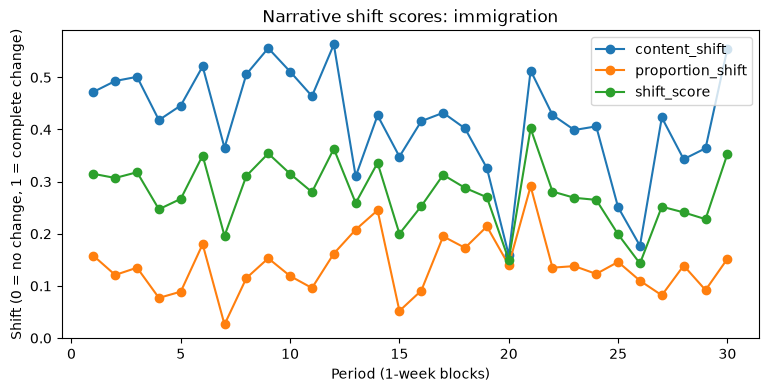

In [22]:
# Peaks=periods where the issue was reframed the most
ax = shift_df.plot(x="to_period", y=["content_shift", "proportion_shift", "shift_score"], marker="o", figsize=(9, 4), title=f"Narrative shift scores: {ISSUE}")
ax.set_xlabel(f"Period ({PERIOD_WEEKS}-week blocks)")
ax.set_ylabel("Shift (0 = no change, 1 = complete change)")

### Feature Table for Supervised Models (one row per week per issue)

**(FYI: Blanks are expected)**:
- The first week of each issue (no previous week to compare).
- An issue's first fitted period (no previous period).
- Periods with fewer than "K × 10" tweets on the issue (too few to fit topics). 
- Weeks with no tweets on the issue (the topic shares are blank).

In [23]:
def shift_between(A, B, threshold=0.2):
    pairs = match_topics(A["H"], B["H"], threshold)

    # Content shift: how much matched topics changed wording (0=same, 1=totally different)
    matched = [s for _, _, s, ok in pairs if ok]
    content_shift = np.mean([1 - s for s in matched]) if matched else 1.0

    # Proportion shift: how much attention moved between topics (0=same mix, 1=completely different)
    a_idx = [a for a, _, _, _ in pairs]
    b_idx = [b for _, b, _, _ in pairs]
    proportion_shift = jensenshannon(A["props"][a_idx], B["props"][b_idx], base=2)

    return {
        "content_shift": round(content_shift, 3),
        "proportion_shift": round(proportion_shift, 3),
        "new_frames": sum(1 for _, _, _, ok in pairs if not ok),
        "shift_score": round((content_shift + proportion_shift) / 2, 3),}


def run_issue(issue, period_weeks=PERIOD_WEEKS, k=K, threshold=0.2):
    """
    #Runs the pilot pipeline above (per period NMF + topic matching) for any issue, without printing.
    Returns one row per period with the shift scores for moving INTO that period from the
    previous fitted period. The first period has nothing to compare to, so it gets no row.
    """
    # Tweets about this issue with at great than or equal to 5 words, grouped into periods
    issue_tweets = df[df[f"issue_{issue}"]].copy()
    issue_tweets = issue_tweets[issue_tweets["cleanedTweet"].str.split().str.len() >= 5].reset_index(drop=True)
    issue_tweets["period"] = issue_tweets["week"] // period_weeks

    # One shared vocabulary per issue so the periods can be compared
    issue_vec = TfidfVectorizer(stop_words=custom_stops, max_df=0.95, min_df=2)
    X_issue = issue_vec.fit_transform(issue_tweets["cleanedTweet"])

    issue_models = {}
    for period, rows in sorted(issue_tweets.groupby("period").indices.items()):
        if len(rows) < k * 10:   # skip periods with too few tweets (same rule as the pilot)
            continue
        period_nmf = NMF(n_components=k, init="nndsvd", random_state=42, max_iter=500)
        W = period_nmf.fit_transform(X_issue[rows])
        issue_models[period] = {"H": period_nmf.components_, "props": W.sum(axis=0) / W.sum()}

    fitted = sorted(issue_models)
    rows = [{"period": p_b, "from_period": p_a, **shift_between(issue_models[p_a], issue_models[p_b], threshold)}
            for p_a, p_b in zip(fitted[:-1], fitted[1:])]
    columns = ["period", "from_period", "content_shift", "proportion_shift", "new_frames", "shift_score"]
    return pd.DataFrame(rows, columns=columns)
run_issue("immigration")

,period,from_period,content_shift,proportion_shift,new_frames,shift_score
0,1,0,0.472,0.158,1,0.315
1,2,1,0.493,0.121,2,0.307
2,3,2,0.501,0.135,1,0.318
3,4,3,0.418,0.077,1,0.247
4,5,4,0.446,0.089,1,0.267
5,6,5,0.521,0.180,2,0.350
6,7,6,0.365,0.026,1,0.196
7,8,7,0.506,0.115,1,0.311
8,9,8,0.556,0.153,2,0.354
9,10,9,0.511,0.119,1,0.315


In [24]:
ISSUES = list(ISSUE_KEYWORDS)

# 1) Tweet counts: one row per week x issue
issue_cols = [f"issue_{i}" for i in ISSUES]
features = (
    df.groupby("week")[issue_cols].sum()
      .rename(columns=lambda c: c.removeprefix("issue_"))
      .reset_index()
      .melt(id_vars="week", var_name="issue", value_name="n_tweets_issue")
)

# 2) Week info: calendar dates (weeks are 7-day blocks starting Wed May 1, 2024),
#    total tweets, and how many days actually have data (weeks 13, 16, 17 have gaps)
first_day = pd.to_datetime(df["date"]).min()
week_info = df.groupby("week").agg(n_tweets_week=("week", "size"), days_with_data=("date", "nunique")).reset_index()
week_info["week_start"] = (first_day + pd.to_timedelta(week_info["week"] * 7, unit="D")).dt.date
week_info["week_end"] = (first_day + pd.to_timedelta(week_info["week"] * 7 + 6, unit="D")).dt.date
features = features.merge(week_info, on="week")

# 3) Issue share: what fraction of that week's tweets mention the issue, and its weekly change
features = features.sort_values(["issue", "week"]).reset_index(drop=True)
features["issue_share"] = features["n_tweets_issue"] / features["n_tweets_week"]
features["issue_share_change"] = features.groupby("issue")["issue_share"].diff()   # blank in week 0

# 4) Shift scores: every week in a period gets that periods scores (blank in each issue's first period
#    and in periods with too few tweets to fit topics)
features["period"] = features["week"] // PERIOD_WEEKS
all_shifts = pd.concat([run_issue(i).assign(issue=i) for i in ISSUES], ignore_index=True)
features = features.merge(all_shifts, on=["issue", "period"], how="left")

# 5) Topic shares: among this issue's tweets that week, the average share of each overall NMF topic
#    (Biden, Trump, ...). These topics have the same meaning every week, unlike the per-period topics.
topic_cols = ["topic_" + name.lower().replace(" ", "_") for name in weekly_topics.columns]
shares = pd.DataFrame(doc_topics, index=docs.index, columns=topic_cols)
shares = shares.div(shares.sum(axis=1), axis=0)   # each tweet's topic weights add up to 1
shares["week"] = df.loc[docs.index, "week"]
weekly_shares = pd.concat(
    [shares[df.loc[docs.index, f"issue_{i}"]].groupby("week")[topic_cols].mean().reset_index().assign(issue=i)
     for i in ISSUES],
    ignore_index=True,
)
features = features.merge(weekly_shares, on=["week", "issue"], how="left")

features = features[
    ["week", "week_start", "week_end", "issue", "n_tweets_issue", "n_tweets_week", "days_with_data",
     "issue_share", "issue_share_change", "period", "from_period", "content_shift", "proportion_shift",
     "new_frames", "shift_score"] + topic_cols
]
features.to_csv("../DataFiles/tk_issue_week_features.csv", index=False)
print(features.shape, "-> saved to DataFiles/tk_issue_week_features.csv")
features.head(12)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


(155, 20) -> saved to DataFiles/tk_issue_week_features.csv


,week,week_start,week_end,issue,n_tweets_issue,n_tweets_week,days_with_data,issue_share,issue_share_change,period,from_period,content_shift,proportion_shift,new_frames,shift_score,topic_biden,topic_trump,topic_harris,topic_maga_movement,topic_partisan_talk
0,0,2024-05-01,2024-05-07,abortion,121,14985,7,0.008075,NaN,0,NaN,NaN,NaN,NaN,NaN,0.317579,0.140708,0.055743,0.074149,0.411821
1,1,2024-05-08,2024-05-14,abortion,126,14991,7,0.008405,0.000330,1,0.0,0.599,0.191,2.0,0.395,0.211536,0.118993,0.053357,0.116388,0.499726
2,2,2024-05-15,2024-05-21,abortion,64,14980,7,0.004272,-0.004133,2,1.0,0.737,0.137,3.0,0.437,0.150161,0.115149,0.054109,0.085011,0.595569
3,3,2024-05-22,2024-05-28,abortion,62,14990,7,0.004136,-0.000136,3,2.0,0.741,0.146,4.0,0.444,0.187780,0.108024,0.056020,0.133403,0.514773
4,4,2024-05-29,2024-06-04,abortion,66,14990,7,0.004403,0.000267,4,3.0,0.689,0.154,3.0,0.422,0.228376,0.101329,0.048371,0.068879,0.553046
5,5,2024-06-05,2024-06-11,abortion,77,14977,7,0.005141,0.000738,5,4.0,0.697,0.170,1.0,0.433,0.249154,0.164862,0.050817,0.104211,0.430956
6,6,2024-06-12,2024-06-18,abortion,119,15023,7,0.007921,0.002780,6,5.0,0.564,0.137,2.0,0.350,0.236687,0.094706,0.036244,0.118774,0.513589
7,7,2024-06-19,2024-06-25,abortion,112,14998,7,0.007468,-0.000454,7,6.0,0.585,0.075,1.0,0.330,0.261183,0.116738,0.078621,0.072855,0.470603
8,8,2024-06-26,2024-07-02,abortion,130,15018,7,0.008656,0.001189,8,7.0,0.603,0.111,2.0,0.357,0.165919,0.207998,0.104936,0.101209,0.419938
9,9,2024-07-03,2024-07-09,abortion,139,15079,7,0.009218,0.000562,9,8.0,0.622,0.226,3.0,0.424,0.141392,0.207997,0.048127,0.084055,0.518429


### Weekly feature table (`features`) and the shift-scoring function (`run_issue`) built above.

In [25]:
# Shared settings for all Week 4 charts: one fixed color per issue, used in every chart
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ISSUE_ORDER = ["foreign_policy", "economy", "immigration", "democracy", "abortion"]  # most to least tweets
ISSUE_LABELS = {"foreign_policy": "Foreign policy", "economy": "Economy", "immigration": "Immigration",
                "democracy": "Democracy", "abortion": "Abortion"}
ISSUE_COLORS = {"foreign_policy": "#2a78d6", "economy": "#eb6834", "immigration": "#1baf7a",
                "democracy": "#eda100", "abortion": "#e87ba4"}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

features["week_start"] = pd.to_datetime(features["week_start"])
score_cols = ["issue_share", "issue_share_change", "content_shift", "proportion_shift", "new_frames", "shift_score"]
features[score_cols] = features[score_cols].apply(pd.to_numeric, errors="coerce")  # blanks become NaN

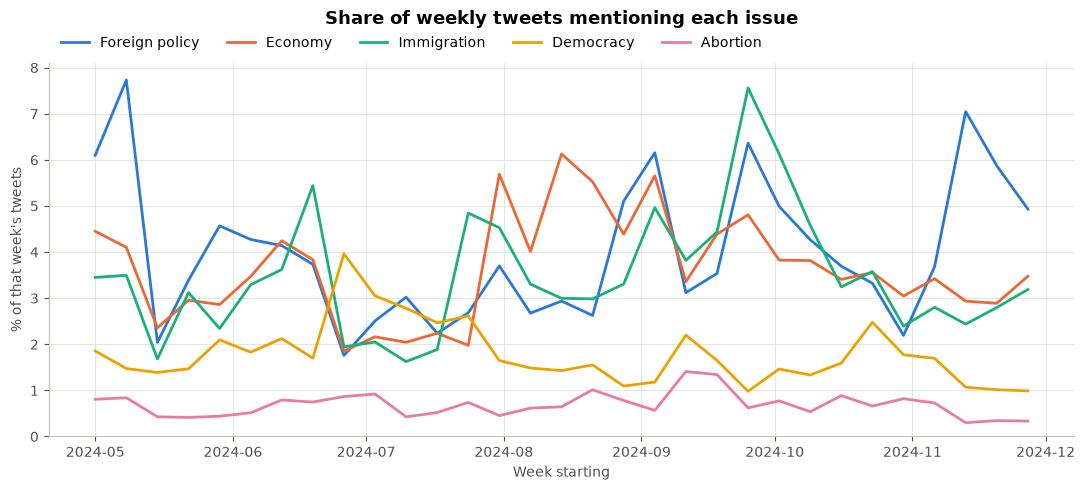

In [26]:
# VISUAL 1: How much attention each issue got, week by week
share = features.pivot(index="week_start", columns="issue", values="issue_share")[ISSUE_ORDER] * 100

fig, ax = plt.subplots(figsize=(11, 5))
for issue in ISSUE_ORDER:
    ax.plot(share.index, share[issue], color=ISSUE_COLORS[issue], linewidth=2, label=ISSUE_LABELS[issue])
ax.set_title("Share of weekly tweets mentioning each issue", pad=28)
ax.set_ylabel("% of that week's tweets")
ax.set_xlabel("Week starting")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5)
fig.tight_layout()
plt.show()

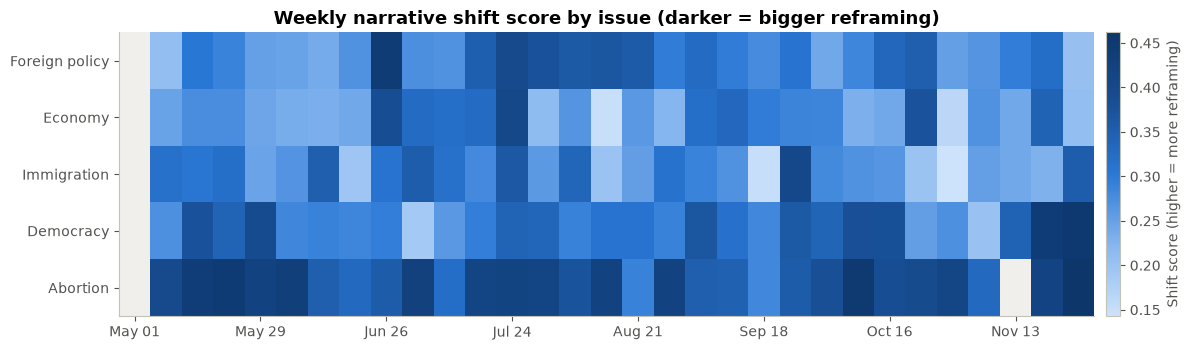

In [27]:
# VISUAL 2: Heatmap of weekly shift scores (how much each issue's framing changed from the week before)
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
blues.set_bad("#f0efec")  # weeks with no score (first week, or too few tweets)

heat = features.pivot(index="issue", columns="week", values="shift_score").loc[ISSUE_ORDER]
week_dates = features.drop_duplicates("week").set_index("week")["week_start"]

fig, ax = plt.subplots(figsize=(13, 3.6))
vals = heat.values.astype(float)
im = ax.imshow(vals, aspect="auto", cmap=blues, vmin=np.nanmin(vals), vmax=np.nanmax(vals))  # color range = actual score range
ax.set_yticks(range(len(ISSUE_ORDER)), [ISSUE_LABELS[i] for i in ISSUE_ORDER])
tick_weeks = heat.columns[::4]
ax.set_xticks([list(heat.columns).index(w) for w in tick_weeks],
              [week_dates[w].strftime("%b %d") for w in tick_weeks])
ax.grid(False)
ax.set_title("Weekly narrative shift score by issue (darker = bigger reframing)")
cbar = fig.colorbar(im, ax=ax, pad=0.01)
cbar.set_label("Shift score (higher = more reframing)")
fig.tight_layout()
plt.show()

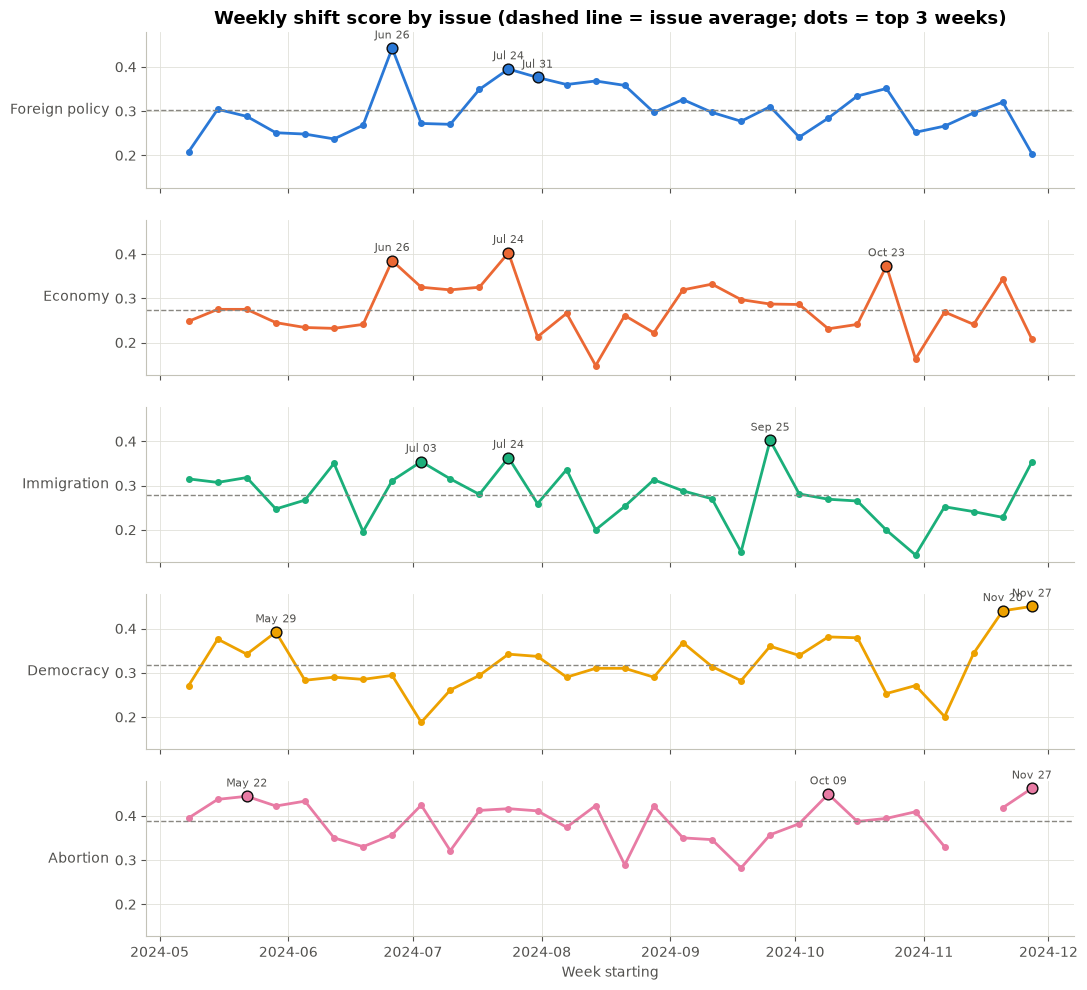

In [28]:
# VISUAL 3: Shift score over time, one small chart per issue, with each issue's top 3 weeks marked
fig, axes = plt.subplots(len(ISSUE_ORDER), 1, figsize=(11, 10), sharex=True, sharey=True)
for ax, issue in zip(axes, ISSUE_ORDER):
    s = features[features["issue"] == issue].set_index("week_start")["shift_score"]
    ax.plot(s.index, s.values, color=ISSUE_COLORS[issue], linewidth=2, marker="o", markersize=4)
    ax.axhline(s.mean(), color="#898781", linewidth=1, linestyle="--")
    top3 = s.nlargest(3)
    ax.scatter(top3.index, top3.values, s=60, color=ISSUE_COLORS[issue], edgecolor="#0b0b0b", zorder=3)
    for d, v in top3.items():
        ax.annotate(d.strftime("%b %d"), (d, v), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=8, color="#52514e")
    ax.set_ylabel(ISSUE_LABELS[issue], rotation=0, ha="right", va="center")
axes[0].set_title("Weekly shift score by issue (dashed line = issue average; dots = top 3 weeks)")
axes[-1].set_xlabel("Week starting") 
fig.tight_layout()
plt.show()

### Topic-to-issue mapping (LDA, 20 topics, full 465k sample)

From the 20-topic LDA run above (candidate names removed). Each topic was read by its top words and assigned to one of our 5 issues; the other 14 topics are candidates, media, reactions, and hashtags rather than issues.

| LDA topic | Top words | Issue |
|---|---|---|
| 7 | illegal, illegals, immigrants, open, border, children | Immigration |
| 15 | inflation, money, economy, tax, jobs, prices | Economy |
| 17 | israel, hamas, gaza, iran, netanyahu, genocide | Foreign policy |
| 10 | ukraine, war, russia (mixed with vote counts) | Foreign policy |
| 13 | women, court, supreme, abortion | Abortion (mixed with courts) |
| 4 | america, democracy, corrupt, law, evil | Democracy (weak) |
| other 14 | candidates, media, insults, hashtags, RFK Jr., debates | Not an issue |

The topic model found the same issues our keywords target, which supports using keywords to pull issue tweets. Healthcare never appeared as a topic at 20 or 30, so it was dropped.

## Sensitivity Analysis

Do the shift scores hold up if we change the settings? We rerun the weekly shift scoring with different choices and compare to our baseline (K = 5 frames per week, match threshold = 0.2, 1-week periods):
- **K = 3 or 7:** fewer or more frames per week
- **Threshold = 0.1 or 0.3:** looser or stricter rule for when two frames count as "the same"
- **2-week periods:** coarser time blocks

If the same issues stay on top and the weekly patterns line up with the baseline, our findings don't depend on these choices.

In [29]:
# SENSITIVITY: rerun shift scoring under different settings (takes a few minutes)
def scores_for(k=5, threshold=0.2, period_weeks=1):
    return pd.concat([run_issue(i, period_weeks=period_weeks, k=k, threshold=threshold).assign(issue=i)
                      for i in ISSUE_ORDER], ignore_index=True)

settings = {
    "Baseline (K=5, t=0.2, 1 wk)": dict(),
    "K = 3": dict(k=3),
    "K = 7": dict(k=7),
    "Threshold = 0.1": dict(threshold=0.1),
    "Threshold = 0.3": dict(threshold=0.3),
    "2-week periods": dict(period_weeks=2),
}
runs = {name: scores_for(**kw) for name, kw in settings.items()}
base = runs["Baseline (K=5, t=0.2, 1 wk)"]
base_mean = base.groupby("issue")["shift_score"].mean()

rows = []
for name, r in runs.items():
    mean_by_issue = r.groupby("issue")["shift_score"].mean().reindex(ISSUE_ORDER)
    row = {"Setting": name}
    row.update({ISSUE_LABELS[i]: round(mean_by_issue[i], 3) for i in ISSUE_ORDER})
    # Do the issues rank in the same order (most to least reframing) as the baseline?
    row["Issue ranking vs baseline (Spearman)"] = round(mean_by_issue.corr(base_mean.reindex(ISSUE_ORDER), method="spearman"), 2)
    # Week-to-week pattern: same periods only (not comparable for 2-week periods)
    if settings[name].get("period_weeks", 1) == 1:
        merged = r.merge(base, on=["issue", "period"], suffixes=("", "_base"))
        corrs = merged.groupby("issue").apply(lambda g: g["shift_score"].corr(g["shift_score_base"], method="spearman"),
                                              include_groups=False)
        row["Weekly pattern vs baseline (median Spearman)"] = round(corrs.median(), 2)
    else:
        row["Weekly pattern vs baseline (median Spearman)"] = "n/a (different periods)"
    rows.append(row)

sensitivity = pd.DataFrame(rows).set_index("Setting")
sensitivity

,Foreign policy,Economy,Immigration,Democracy,Abortion,Issue ranking vs baseline (Spearman),Weekly pattern vs baseline (median Spearman)
Setting,,,,,,,
"Baseline (K=5, t=0.2, 1 wk)",0.302,0.274,0.277,0.318,0.387,1.0,1.0
K = 3,0.251,0.251,0.244,0.305,0.340,0.9,0.42
K = 7,0.290,0.279,0.295,0.327,0.376,0.9,0.44
Threshold = 0.1,0.321,0.294,0.300,0.354,0.417,1.0,0.83
Threshold = 0.3,0.278,0.263,0.269,0.300,0.365,1.0,0.91
2-week periods,0.247,0.246,0.254,0.279,0.332,0.9,n/a (different periods)


**Topic count (5, 20, 30):** see "Testing More Topics" above. At 5 topics the models grouped tweets by candidate; at 20 (LDA) issue topics appeared; 30 mostly split those issues into smaller pieces.

## Results Analysis

In [30]:
# RESULTS: summary of each issue's weekly shift scores, and its 3 biggest reframing weeks
summary_rows = []
for issue in ISSUE_ORDER:
    f = features[features["issue"] == issue].dropna(subset=["shift_score"])
    top3 = f.nlargest(3, "shift_score")
    summary_rows.append({
        "Issue": ISSUE_LABELS[issue],
        "Total tweets": int(features.loc[features["issue"] == issue, "n_tweets_issue"].sum()),
        "Weeks scored": len(f),
        "Avg shift score": round(f["shift_score"].mean(), 3),
        "Avg content shift": round(f["content_shift"].mean(), 3),
        "Avg proportion shift": round(f["proportion_shift"].mean(), 3),
        "Top 3 weeks (shift score)": ", ".join(f"{d:%b %d} ({v:.2f})" for d, v in zip(top3["week_start"], top3["shift_score"])),
        # Does reframing happen in the same weeks attention changes? (+1 = always together, 0 = unrelated)
        "Shift vs attention change (Spearman)": round(f["shift_score"].corr(f["issue_share_change"].abs(), method="spearman"), 2),
    })
results = pd.DataFrame(summary_rows).set_index("Issue")
results

,Total tweets,Weeks scored,Avg shift score,Avg content shift,Avg proportion shift,Top 3 weeks (shift score),Shift vs attention change (Spearman)
Issue,,,,,,,
Foreign policy,18668,30,0.302,0.468,0.136,"Jun 26 (0.44), Jul 24 (0.40), Jul 31 (0.38)",-0.04
Economy,16934,30,0.274,0.404,0.143,"Jul 24 (0.40), Jun 26 (0.39), Oct 23 (0.37)",-0.21
Immigration,16178,30,0.277,0.417,0.139,"Sep 25 (0.40), Jul 24 (0.36), Jul 03 (0.35)",0.16
Democracy,8319,30,0.318,0.491,0.144,"Nov 27 (0.45), Nov 20 (0.44), May 29 (0.39)",-0.35
Abortion,3192,29,0.387,0.630,0.145,"Nov 27 (0.46), Oct 09 (0.45), May 22 (0.44)",-0.37


## Stream Plot: Issue Attention Over the Campaign (#30)

Each band is one issue; its thickness is the number of tweets mentioning that issue that week. Bands are centered so the overall shape shows how total issue talk rose and fell, and each band's width shows its share.

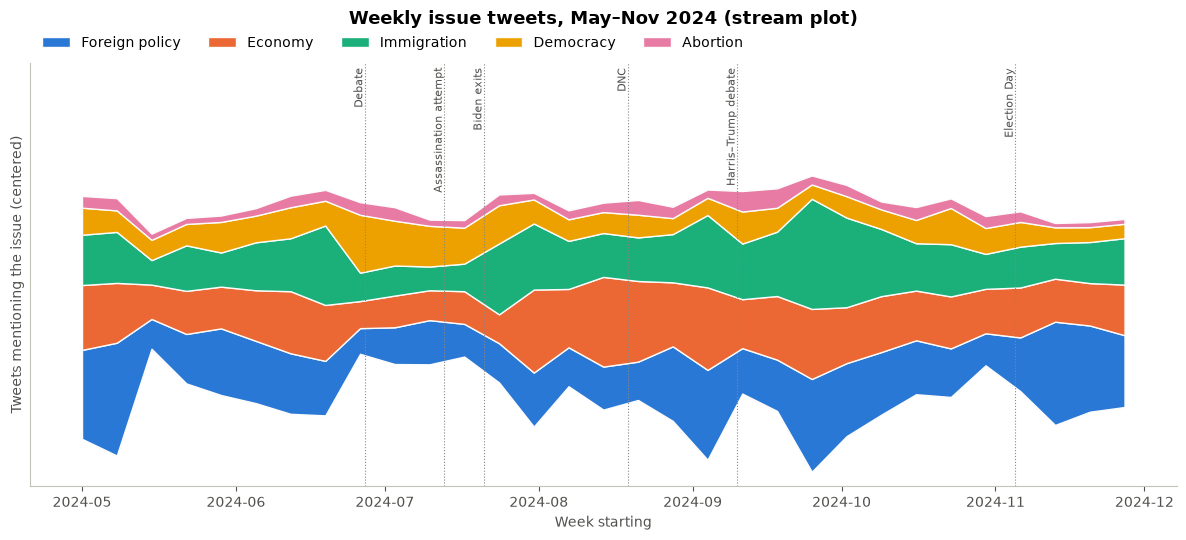

In [31]:
# STREAM PLOT: weekly tweet counts per issue, stacked around a centered baseline
counts = features.pivot(index="week_start", columns="issue", values="n_tweets_issue")[ISSUE_ORDER]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.stackplot(counts.index, [counts[i] for i in ISSUE_ORDER], baseline="wiggle",
             colors=[ISSUE_COLORS[i] for i in ISSUE_ORDER], labels=[ISSUE_LABELS[i] for i in ISSUE_ORDER],
             edgecolor="#fcfcfb", linewidth=1)

# Campaign events as reference lines
events = {"Debate": "2024-06-27", "Assassination attempt": "2024-07-13", "Biden exits": "2024-07-21",
          "DNC": "2024-08-19", "Harris–Trump debate": "2024-09-10", "Election Day": "2024-11-05"}
lo, hi = ax.get_ylim()
pad = (hi - lo) * 0.3            # empty band at the top for the event labels
ax.set_ylim(lo, hi + pad)
for name, d in events.items():
    d = pd.Timestamp(d)
    ax.axvline(d, color="#898781", linewidth=0.8, linestyle=":")
    ax.text(d, hi + pad * 0.95, name, rotation=90, va="top", ha="right", fontsize=8, color="#52514e")

ax.set_title("Weekly issue tweets, May–Nov 2024 (stream plot)", pad=28)
ax.set_xlabel("Week starting")
ax.set_ylabel("Tweets mentioning the issue (centered)")
ax.set_yticks([])  # a centered stream has no meaningful zero; band thickness is the measure
ax.grid(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5)
fig.tight_layout()
plt.show()

## Keyword Check: Do the Issue Keywords Catch the Right Tweets? (#57)

Error analysis for the keyword step. Two checks:
1. **Which words actually triggered each issue** (automatic): shows if a pattern is catching the wrong words, e.g. `roe` inside "heroes" or `tax` inside "syntax".
2. **Hand check** (manual): 20 random tweets per issue (100 total) saved to a CSV. Mark each one 1 (really about the issue) or 0 (not), then run the precision cell.

In [32]:
# CHECK 1: the full words that triggered each issue's pattern, most common first
import re

trigger_rows = []
for issue in ISSUE_ORDER:
    pattern = re.compile(r"\b\w*(?:" + ISSUE_KEYWORDS[issue] + r")\w*\b")
    hits = text[df[f"issue_{issue}"]].str.findall(pattern).explode().dropna()
    for word, n in hits.value_counts().head(12).items():
        trigger_rows.append({"Issue": ISSUE_LABELS[issue], "Matched word": word, "Tweets": n})

triggers = pd.DataFrame(trigger_rows)
for issue_label, g in triggers.groupby("Issue", sort=False):
    print(f"\n{issue_label}: " + ", ".join(f"{w} ({n})" for w, n in zip(g["Matched word"], g["Tweets"])))


Foreign policy: israel (7091), ukraine (5551), russia (4322), china (2315), russian (2034), gaza (1970), israeli (975), nato (941), russians (289), israelis (224), gazagenocide (64), gazans (38)

Economy: inflation (4259), economy (4251), tax (3529), jobs (2422), prices (1630), taxes (1511), economic (1406), taxpayers (629), taxpayer (549), groceries (421), gas prices (368), economics (307)

Immigration: border (7908), illegals (2882), immigrants (2004), immigration (1936), borders (1337), migrants (967), illegal aliens (803), immigrant (535), deport (448), migrant (422), asylum (351), deportation (257)

Democracy: democracy (4698), fascist (1565), insurrection (608), fascists (486), jan 6 (252), january 6th (236), january 6 (230), insurrectionist (208), jan 6th (172), stolen election (109), insurrectionists (97), voteblue2024protectdemocracy (74)

Abortion: abortion (2141), roe (376), abortions (352), ivf (229), reproductive (213), pro-life (161), pro life (83), prolife (54), pro-cho

In [33]:
# CHECK 2a: save 20 random tweets per issue for hand-checking (fill in the 'correct' column with 1 or 0)
CHECK_FILE = "../DataFiles/tk_keyword_check.csv"
sample_rows = []
for issue in ISSUE_ORDER:
    pattern = re.compile(r"\b\w*(?:" + ISSUE_KEYWORDS[issue] + r")\w*\b")
    picks = df[df[f"issue_{issue}"]].sample(20, random_state=42)
    for idx, row in picks.iterrows():
        sample_rows.append({"issue": issue, "week": row["week"],
                            "matched_words": ", ".join(sorted(set(pattern.findall(text[idx])))),
                            "tweet": row["cleanedTweet"], "correct": ""})
pd.DataFrame(sample_rows).to_csv(CHECK_FILE, index=False)
print(f"Saved {len(sample_rows)} tweets to {CHECK_FILE}. Open it, mark 'correct' as 1 or 0, save, then run the next cell.")

Saved 100 tweets to ../DataFiles/tk_keyword_check.csv. Open it, mark 'correct' as 1 or 0, save, then run the next cell.


In [34]:
# CHECK 2b: keyword precision per issue (run after filling in the CSV)
checked = pd.read_csv(CHECK_FILE)
checked["correct"] = pd.to_numeric(checked["correct"], errors="coerce")
done = checked.dropna(subset=["correct"])
if done.empty:
    print("No rows marked yet: fill in the 'correct' column in", CHECK_FILE)
else:
    precision = (done.groupby("issue")["correct"].agg(checked="count", precision="mean")
                     .reindex(ISSUE_ORDER).rename(index=ISSUE_LABELS))
    precision["precision"] = precision["precision"].round(2)
    print(f"Overall keyword precision: {done['correct'].mean():.2f} ({int(done['correct'].sum())} of {len(done)} correct)")
    display(precision)
    print("\nMisses to describe in the report:")
    display(done[done["correct"] == 0][["issue", "matched_words", "tweet"]])

No rows marked yet: fill in the 'correct' column in ../DataFiles/tk_keyword_check.csv
